# Dados e qualidade da abertura da B3

Este notebook é o roteiro da **Fase 1**: conhecer os arquivos, tornar o tempo comparável em UTC, gerar Parquets e investigar a cobertura. As saídas são calculadas com os datasets reais do projeto.

Vamos percorrer: **inventário → amostras brutas → horários → Parquet → cobertura → WIN/WDO → intervalos externos → conclusões**.

Os ajustes ficam explícitos nas células. A leitura, a padronização e os diagnósticos reutilizáveis estão em `src/abertura`. Os arquivos brutos são a referência imutável; não interpolamos preços. Regras operacionais, modelos e ajustes de rolagem pertencem a etapas posteriores.

## 1. Ambiente e parâmetros

Na raiz do projeto, prepare o ambiente com:

```bash
uv sync --locked --group notebook
```

A hipótese de fuso dos CSVs do professor é **America/Sao_Paulo**. A distribuição das aberturas permite verificar sua coerência interna, mas a confirmação com a corretora continua pendente.

In [1]:
from pathlib import Path
from copy import deepcopy
import importlib.metadata as metadata
import sys
import json
import gc

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/assets.yaml").is_file())

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from abertura.interim import build_all, raw_files
from abertura.io import read_mt5_csv, read_dukascopy_csv
from abertura.sessions import b3_sessions, daily_sessions, missing_session_dates
from abertura.quality import coverage_tables, candle_gaps, late_opens_by_quarter, missing_runs

pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 20)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)

In [2]:
# Ajustes desta exploração. Alterar o fuso reconstrói os Parquets dos alvos.
ATIVO_B3 = "win"
ATIVO_EXTERNO = "spx"
DIA_EXEMPLO_BRT = "2026-03-10"
FUSO_MT5 = "America/Sao_Paulo"
MINUTOS_JANELA = 60
MINUTOS_AUSENTES_PARA_INSPECIONAR = 15
parametros = yaml.safe_load((ROOT / "config/params.yaml").read_text())
ATRASO_MAXIMO_ABERTURA = parametros["sample"]["max_open_delay_minutes"]

config = deepcopy(yaml.safe_load((ROOT / "config/assets.yaml").read_text()))
for asset in config["assets"].values():
    if asset["source"] == "professor":
        asset["timezone"] = FUSO_MT5
assert config["assets"][ATIVO_B3]["source"] == "professor"
assert config["assets"][ATIVO_EXTERNO]["source"] == "dukascopy"

## 2. Quais datasets temos?

São **13 ativos externos** e **2 alvos**. WIN/WDO vêm dos arquivos do professor; o novo download do MT5 depende do colega com Windows. Os instrumentos externos são os fornecidos pela Dukascopy e podem ser proxies/CFDs dos índices citados. TOPIX, CSI 300, Shanghai Composite e US T-Bond ficaram fora da coleta atual.

O inventário abaixo considera somente o histórico definido na configuração, sem misturar o piloto.

In [3]:
inventario = pd.DataFrame([
    {"ativo": asset_id, "fonte": asset["source"], "simbolo": asset["symbol"],
     "arquivos_brutos": len(raw_files(asset_id, asset, ROOT / "data"))}
    for asset_id, asset in config["assets"].items()
])
display(inventario)

,ativo,fonte,simbolo,arquivos_brutos
0,win,professor,WIN$N,1
1,wdo,professor,WDO$N,1
2,spx,dukascopy,usa500idxusd,74
3,ndx,dukascopy,usatechidxusd,74
4,sx5e,dukascopy,eusidxeur,74
5,ftse,dukascopy,gbridxgbp,74
6,nikkei,dukascopy,jpnidxjpy,74
7,a50,dukascopy,chiidxusd,74
8,brent,dukascopy,brentcmdusd,74
9,gold,dukascopy,xauusd,74


### Amostras como vieram da fonte

Observe os nomes das colunas, os preços e o formato do tempo. No MT5, `<DATE>` e `<TIME>` não têm fuso explícito. Na Dukascopy, `timestamp` é epoch em **milissegundos UTC**. O volume tem significados diferentes entre fontes; não vamos misturar volume real com volume de ticks. `SPREAD` será descartado.

In [4]:
for asset_id in ["win", "wdo", ATIVO_EXTERNO]:
    asset = config["assets"][asset_id]
    path = raw_files(asset_id, asset, ROOT / "data")[0]
    display(Markdown(f"**{asset_id.upper()}** — `{path.relative_to(ROOT)}`"))
    display(pd.read_csv(path, sep="\t" if asset["source"] == "professor" else ",", nrows=3))

**WIN** — `data/raw/target/WIN.csv`

,<DATE>,<TIME>,<OPEN>,<HIGH>,<LOW>,<CLOSE>,<TICKVOL>,<VOL>,<SPREAD>
0,2020.10.15,11:49:00,98565,98575,98530,98575,2373,9001,5
1,2020.10.15,11:50:00,98570,98625,98570,98600,5483,19111,5
2,2020.10.15,11:51:00,98595,98600,98535,98580,4572,17663,5


**WDO** — `data/raw/target/WDO.csv`

,<DATE>,<TIME>,<OPEN>,<HIGH>,<LOW>,<CLOSE>,<TICKVOL>,<VOL>,<SPREAD>
0,2020.09.17,14:08:00,5248.5,5249.0,5244.5,5247.0,3244,10451,500
1,2020.09.17,14:09:00,5247.0,5249.0,5246.5,5247.0,864,4090,500
2,2020.09.17,14:10:00,5247.0,5249.5,5247.0,5248.5,1109,3164,500


**SPX** — `data/raw/feature/spx/2020-09-01_2020-10-01.csv`

,timestamp,open,high,low,close,volume
0,1598918400000,3498.652,3500.300,3498.543,3499.246,0.24144
1,1598918460000,3499.237,3499.800,3498.734,3499.252,0.21768
2,1598918520000,3499.255,3500.555,3499.255,3499.743,0.13827


## 3. O mesmo instante em UTC e em Brasília

O padrão terá seis colunas: `datetime, open, high, low, close, volume`. O tempo fica em **`datetime64[ns, UTC]`**; a conversão para Brasília abaixo é só para exibir.

Para o CSV MT5, aplicamos o fuso configurado e convertemos para UTC. Uma futura exportação de `copy_rates_range` usa epoch em segundos já em UTC e tem leitor separado (`read_mt5_api_csv`), evitando aplicar o deslocamento duas vezes.

Duplicatas idênticas podem ser eliminadas. Se preço ou volume diferirem no mesmo timestamp, a conversão é interrompida para investigar a fonte.

In [5]:
amostra = read_mt5_csv(raw_files("win", config["assets"]["win"], ROOT / "data")[0], timezone=FUSO_MT5)
comparacao_tempo = amostra.head(5)[["datetime", "open", "close", "volume"]].copy()
comparacao_tempo.insert(1, "exibicao_brt", comparacao_tempo.datetime.dt.tz_convert("America/Sao_Paulo"))
display(comparacao_tempo)
display(amostra.dtypes.to_frame("tipo_padronizado"))
print("Volume do professor:", amostra.attrs["volume_column"])
del amostra
gc.collect();

,datetime,exibicao_brt,open,close,volume
0,2020-10-15 14:49:00+00:00,2020-10-15 11:49:00-03:00,98565.0,98575.0,9001.0
1,2020-10-15 14:50:00+00:00,2020-10-15 11:50:00-03:00,98570.0,98600.0,19111.0
2,2020-10-15 14:51:00+00:00,2020-10-15 11:51:00-03:00,98595.0,98580.0,17663.0
3,2020-10-15 14:52:00+00:00,2020-10-15 11:52:00-03:00,98575.0,98615.0,13143.0
4,2020-10-15 14:53:00+00:00,2020-10-15 11:53:00-03:00,98620.0,98610.0,13702.0


,tipo_padronizado
datetime,"datetime64[ns, UTC]"
open,float64
high,float64
low,float64
close,float64
volume,float64


Volume do professor: <VOL>


## 4. Gerar os Parquets

Esta célula executa a padronização dos 15 ativos. Cada arquivo vai para `data/interim/<ativo>_m1.parquet`, com compressão Zstandard via pyarrow.

A conversão processa um ativo por vez e valida os preços e a ordem temporal.

In [6]:
padronizacao = build_all(ROOT, config=config)
display(padronizacao)
print("Total de candles padronizados:", f"{padronizacao.rows.sum():,}")
print("Duplicatas idênticas removidas:", int(padronizacao.duplicates_removed.sum()))

win: 757,716 candles


wdo: 717,232 candles


spx: 2,081,188 candles


ndx: 2,111,355 candles


sx5e: 1,166,863 candles


ftse: 2,063,447 candles


... (7 outputs left out)

eurusd: 2,287,051 candles


usdjpy: 2,294,935 candles


,asset,rows,source_rows,duplicates_removed,first_utc,last_utc,parquet_bytes
0,win,757716,757716,0,2020-10-15T14:49:00+00:00,2026-09-25T21:24:00+00:00,12493539
1,wdo,717232,717232,0,2020-09-17T17:08:00+00:00,2026-04-01T19:07:00+00:00,10405458
2,spx,2081188,2081188,0,2020-09-01T00:00:00+00:00,2026-10-30T20:14:00+00:00,45503460
3,ndx,2111355,2111355,0,2020-09-01T00:00:00+00:00,2026-10-30T20:14:00+00:00,52020988
4,sx5e,1166863,1166863,0,2020-09-01T06:00:00+00:00,2026-10-30T20:59:00+00:00,20217836
5,ftse,2063447,2063447,0,2020-09-01T00:00:00+00:00,2026-10-30T21:00:00+00:00,48017035
6,nikkei,2013398,2013398,0,2020-09-01T00:00:00+00:00,2026-10-30T20:14:00+00:00,33895497
7,a50,1713745,1713745,0,2020-09-01T01:00:00+00:00,2026-10-30T20:29:00+00:00,29085133
8,brent,1976028,1976028,0,2020-09-01T00:00:00+00:00,2026-10-30T20:59:00+00:00,32373320
9,gold,2186890,2186890,0,2020-09-01T00:00:00+00:00,2026-10-30T20:59:00+00:00,43991677


Total de candles padronizados: 27,703,105
Duplicatas idênticas removidas: 0


## 5. Períodos e cobertura mensal

**Contagem de registros não é garantia de cobertura completa.** Os ativos têm calendários, pausas e durações diferentes; a fonte também omite candles com volume zero.

Na imagem, cada linha é um ativo e cada coluna é um mês. A escala compara a contagem com o máximo mensal do próprio ativo. Zero significa que não observamos registros naquele mês; abaixo vamos distinguir falta de histórico de ausência dentro dele.

In [7]:
cobertura, contagem_mensal = coverage_tables(ROOT / "data/interim", config["assets"])
display(cobertura.round({"parquet_mb": 2}))
contagem_mensal.to_csv(ROOT / "reports/cobertura_mensal.csv", index_label="mes_utc")
print("Tamanho total dos Parquets (MB):", round(cobertura.parquet_mb.sum(), 1))

,asset,source,rows,first_utc,last_utc,utc_dates_with_data,parquet_mb
0,win,professor,757716,2020-10-15 14:49:00+00:00,2026-09-25 21:24:00+00:00,1368,12.49
1,wdo,professor,717232,2020-09-17 17:08:00+00:00,2026-04-01 19:07:00+00:00,1288,10.41
2,spx,dukascopy,2081188,2020-09-01 00:00:00+00:00,2026-10-30 20:14:00+00:00,1919,45.50
3,ndx,dukascopy,2111355,2020-09-01 00:00:00+00:00,2026-10-30 20:14:00+00:00,1919,52.02
4,sx5e,dukascopy,1166863,2020-09-01 06:00:00+00:00,2026-10-30 20:59:00+00:00,1577,20.22
5,ftse,dukascopy,2063447,2020-09-01 00:00:00+00:00,2026-10-30 21:00:00+00:00,1900,48.02
6,nikkei,dukascopy,2013398,2020-09-01 00:00:00+00:00,2026-10-30 20:14:00+00:00,1916,33.90
7,a50,dukascopy,1713745,2020-09-01 01:00:00+00:00,2026-10-30 20:29:00+00:00,1581,29.09
8,brent,dukascopy,1976028,2020-09-01 00:00:00+00:00,2026-10-30 20:59:00+00:00,1593,32.37
9,gold,dukascopy,2186890,2020-09-01 00:00:00+00:00,2026-10-30 20:59:00+00:00,1917,43.99


Tamanho total dos Parquets (MB): 529.4


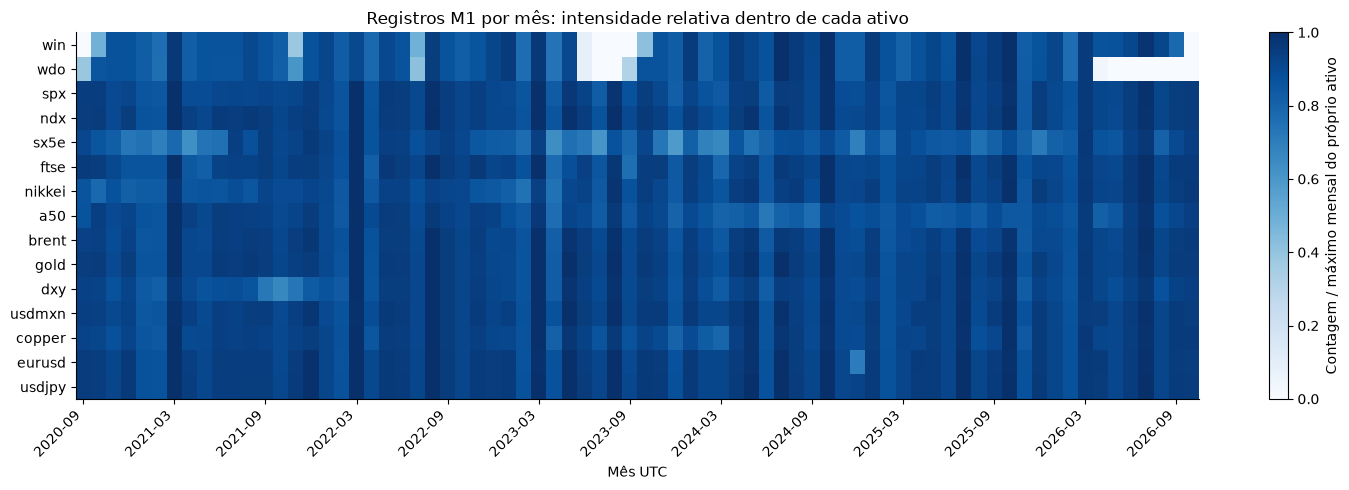

In [8]:
relativa = contagem_mensal.T.div(contagem_mensal.T.max(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(15, 5))
image = ax.imshow(relativa.to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_yticks(range(len(relativa)), relativa.index)
ticks = range(0, len(relativa.columns), 6)
ax.set_xticks(list(ticks), [relativa.columns[i] for i in ticks], rotation=45, ha="right")
ax.set_title("Registros M1 por mês: intensidade relativa dentro de cada ativo")
ax.set_xlabel("Mês UTC")
fig.colorbar(image, ax=ax, label="Contagem / máximo mensal do próprio ativo")
fig.tight_layout()
fig.savefig(FIGURES / "01_cobertura_mensal.png", dpi=140)
plt.show()

## 6. Calendário e horários de WIN/WDO

Usamos `exchange-calendars/BVMF` como referência para **datas de pregão e aberturas especiais**. Não aplicamos o horário de ações aos futuros: para WIN/WDO, a abertura regular esperada é **09:00 BRT**. O fechamento é medido pelo último candle observado em cada dia, sem um horário fixo no código.

A Quarta-feira de Cinzas tem abertura especial às 13h. Isso está documentado, por exemplo, no [calendário oficial da B3 de 2026](https://www.b3.com.br/pt_br/noticias/calendario-de-negociacao-da-b3-confira-o-funcionamento-da-bolsa-em-2026.htm). A [implementação do calendário](https://github.com/gerrymanoim/exchange_calendars/blob/master/exchange_calendars/exchange_calendar_bvmf.py) considera mudanças históricas de feriados. Datas observadas fora dessa referência são sinalizadas para revisão, não apagadas.

In [9]:
INICIO_AUDITORIA = pd.Timestamp(config["period"]["start"])
FIM_AUDITORIA = cobertura.last_utc.max().tz_convert("America/Sao_Paulo").tz_localize(None).normalize()
calendario = b3_sessions(INICIO_AUDITORIA, FIM_AUDITORIA)
print("Pregões de referência:", len(calendario), "| de", INICIO_AUDITORIA.date(), "a", FIM_AUDITORIA.date())
display(calendario[calendario.is_special_open])

Pregões de referência: 1536 | de 2020-09-01 a 2026-10-30


,is_special_open,expected_open_utc
date_brt,,
2021-02-17,True,2021-02-17 16:00:00+00:00
2022-03-02,True,2022-03-02 16:00:00+00:00
2023-02-22,True,2023-02-22 16:00:00+00:00
2024-02-14,True,2024-02-14 16:00:00+00:00
2025-03-05,True,2025-03-05 16:00:00+00:00
2026-02-18,True,2026-02-18 16:00:00+00:00


In [10]:
sessoes, ausencias, blocos_ausentes = {}, {}, {}
resumos_b3 = []
for asset_id in ["win", "wdo"]:
    frame = pd.read_parquet(ROOT / f"data/interim/{asset_id}_m1.parquet")
    sessoes[asset_id] = daily_sessions(frame, calendario, window_minutes=MINUTOS_JANELA,
                                       max_open_delay_minutes=ATRASO_MAXIMO_ABERTURA)
    ausencias[asset_id] = missing_session_dates(frame, calendario)
    blocos_ausentes[asset_id] = missing_runs(ausencias[asset_id], calendario)
    daily, missing = sessoes[asset_id], ausencias[asset_id]
    resumos_b3.append({
        "ativo": asset_id, "dias_observados": len(daily),
        "pregoes_ausentes_internos": int(missing.reason.eq("missing_session_internal").sum()),
        "antes_do_historico": int(missing.reason.eq("before_history").sum()),
        "apos_o_historico": int(missing.reason.eq("after_history").sum()),
        "janela_inicial_incompleta": int(daily.opening_window_missing.gt(0).sum()),
        "abertura_tardia": int(daily.open_delay_minutes.between(1, ATRASO_MAXIMO_ABERTURA).sum()),
        "abertura_acima_do_limite": int(daily.open_delay_minutes.gt(ATRASO_MAXIMO_ABERTURA).sum()),
        "pregoes_elegiveis": int(daily.eligible_regular_opening.sum()),
        "fora_do_calendario": int((~daily.is_expected_session).sum()),
        "abertura_regular_mais_frequente": daily.loc[~daily.is_special_open, "first_brt"].mode().iloc[0],
    })
    del frame
    gc.collect()
resumo_b3 = pd.DataFrame(resumos_b3)
display(resumo_b3)

,ativo,dias_observados,pregoes_ausentes_internos,antes_do_historico,apos_o_historico,janela_inicial_incompleta,abertura_tardia,abertura_acima_do_limite,pregoes_elegiveis,fora_do_calendario,abertura_regular_mais_frequente
0,win,1368,114,30,24,8,214,4,1351,0,09:00
1,wdo,1288,91,11,146,8,118,3,1272,0,09:00


### Aberturas e últimos candles observados

A predominância de abertura às 09:00 é compatível com a hipótese de horário de Brasília no CSV. Isso **não identifica sozinho o fuso do servidor da corretora**.

O gráfico da direita mostra o horário de abertura do último candle disponível, não uma declaração de que aquele candle seja o fechamento oficial. Dias truncados ou com ausência no fim ainda precisam de investigação.

A **abertura de cada dia é o primeiro candle observado**, e a janela inicial é contada a partir dele. Um dia só perde a elegibilidade se esse candle vier mais de `ATRASO_MAXIMO_ABERTURA` minutos depois da referência ou se faltarem minutos na janela. Os dias continuam no Parquet de minutos; a elegibilidade é apenas a marcação `is_eligible` da tabela diária.

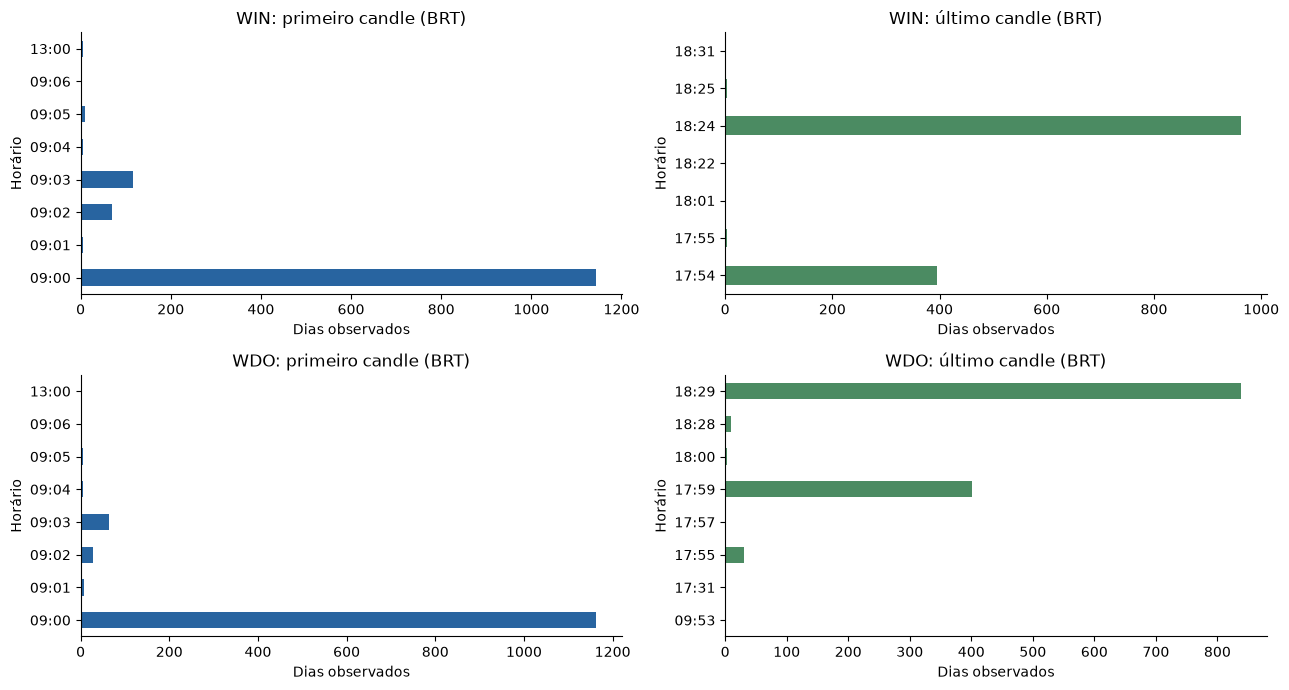

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for row, asset_id in enumerate(["win", "wdo"]):
    daily = sessoes[asset_id]
    daily.first_brt.value_counts().head(8).sort_index().plot.barh(ax=axes[row, 0], color="#2864a0")
    daily.last_brt.value_counts().head(8).sort_index().plot.barh(ax=axes[row, 1], color="#4b8b62")
    axes[row, 0].set_title(f"{asset_id.upper()}: primeiro candle (BRT)")
    axes[row, 1].set_title(f"{asset_id.upper()}: último candle (BRT)")
    for ax in axes[row]:
        ax.set_xlabel("Dias observados")
        ax.set_ylabel("Horário")
fig.tight_layout()
fig.savefig(FIGURES / "02_horarios_b3.png", dpi=140)
plt.show()

### Aberturas depois da referência, por trimestre

No WIN, a falta de candle às 09:00 deixou de ser rara a partir de 2025 T4, com primeiro candle em geral às 09:02 ou 09:03. O WDO não acompanha esse padrão no mesmo período. Medição de 02/11/2026: desde outubro de 2025, a mediana do volume até 09:10 foi de 672 mil nos dias que abrem às 09:00 e de 654 mil nos demais. Isso indica abertura real mais tarde, não candles perdidos, mas ainda falta confirmar com a corretora.

Por isso a entrada do backtest é o candle seguinte ao primeiro, e não um candle 09:01 fixo (seção 7 do `AGENTS.md`).

In [12]:
atrasos = pd.concat([late_opens_by_quarter(sessoes[asset_id]).add_prefix(f"{asset_id}_")
                     for asset_id in ["win", "wdo"]], axis=1).sort_index().convert_dtypes()
atrasos.index.name = "trimestre"
with pd.option_context("display.max_rows", None):
    display(atrasos)

,win_pregoes,win_com_atraso,win_pct,wdo_pregoes,wdo_com_atraso,wdo_pct
trimestre,,,,,,
2020Q3,<NA>,<NA>,<NA>,10,7,70.0
2020Q4,52,12,23.1,61,18,29.5
2021Q1,59,15,25.4,59,23,39.0
2021Q2,62,1,1.6,62,15,24.2
2021Q3,64,4,6.2,64,12,18.8
2021Q4,49,8,16.3,55,9,16.4
2022Q1,61,2,3.3,61,2,3.3
2022Q2,62,5,8.1,62,2,3.2
2022Q3,56,3,5.4,55,1,1.8


### Quais pregões estão ausentes?

Separamos três situações: **antes do primeiro registro da fonte**, **depois do último** e **pregões ausentes entre esses limites**. Apenas a terceira é tratada aqui como ausência interna.

Os blocos abaixo agrupam pregões consecutivos do calendário, atravessando fins de semana e feriados. Não contamos um fim de semana como se fossem candles perdidos.

In [13]:
for asset_id in ["win", "wdo"]:
    display(Markdown(f"**{asset_id.upper()} — maiores blocos de pregões ausentes dentro do histórico**"))
    internal = blocos_ausentes[asset_id].query("reason == 'missing_session_internal'")
    display(internal.sort_values("missing_sessions", ascending=False).head(10))
    display(Markdown(f"**Dias com janela inicial de {MINUTOS_JANELA} minutos incompleta — {asset_id.upper()}**"))
    display(sessoes[asset_id].loc[sessoes[asset_id].opening_window_missing.gt(0),
                                 ["first_brt", "last_brt", "has_expected_open", "opening_window_missing"]].head(12))

**WIN — maiores blocos de pregões ausentes dentro do histórico**

,first_date,last_date,missing_sessions,reason
3,2023-06-05,2023-10-16,93,missing_session_internal
1,2021-11-16,2021-12-01,12,missing_session_internal
2,2022-07-15,2022-07-27,9,missing_session_internal


**Dias com janela inicial de 60 minutos incompleta — WIN**

,first_brt,last_brt,has_expected_open,opening_window_missing
date_brt,,,,
2021-10-19,09:00,17:54,True,1
2022-09-13,09:00,17:54,True,1
2022-10-13,09:00,17:54,True,1
2023-10-17,16:58,17:54,False,3
2024-06-07,09:00,18:24,True,1
2025-06-03,09:00,18:24,True,52
2025-08-21,09:00,18:24,True,43
2026-07-10,09:00,18:24,True,1


**WDO — maiores blocos de pregões ausentes dentro do histórico**

,first_date,last_date,missing_sessions,reason
3,2023-06-05,2023-09-19,75,missing_session_internal
2,2022-07-15,2022-07-28,10,missing_session_internal
1,2021-11-24,2021-12-01,6,missing_session_internal


**Dias com janela inicial de 60 minutos incompleta — WDO**

,first_brt,last_brt,has_expected_open,opening_window_missing
date_brt,,,,
2020-10-14,09:00,17:55,True,5
2021-05-12,09:00,17:59,True,1
2021-07-13,09:00,17:59,True,3
2021-08-06,09:00,17:59,True,1
2021-11-23,09:00,09:53,True,6
2022-07-29,17:31,17:59,False,31
2022-09-09,09:00,17:59,True,2
2022-10-13,09:00,17:59,True,2


### Um pregão de perto

Escolha `DIA_EXEMPLO_BRT` na célula de parâmetros. Lemos somente aquele dia do Parquet. Os pontos são fechamentos observados; não preenchemos minutos ausentes para desenhar a série.

,datetime,open,high,low,close,volume
0,2026-03-10 12:00:00+00:00,183790.0,184180.0,183790.0,184065.0,86297.0
1,2026-03-10 12:01:00+00:00,184060.0,184325.0,183710.0,184190.0,103162.0
2,2026-03-10 12:02:00+00:00,184185.0,184270.0,183515.0,183575.0,97542.0
3,2026-03-10 12:03:00+00:00,183570.0,183610.0,183235.0,183255.0,90014.0
4,2026-03-10 12:04:00+00:00,183250.0,183465.0,183235.0,183350.0,59172.0


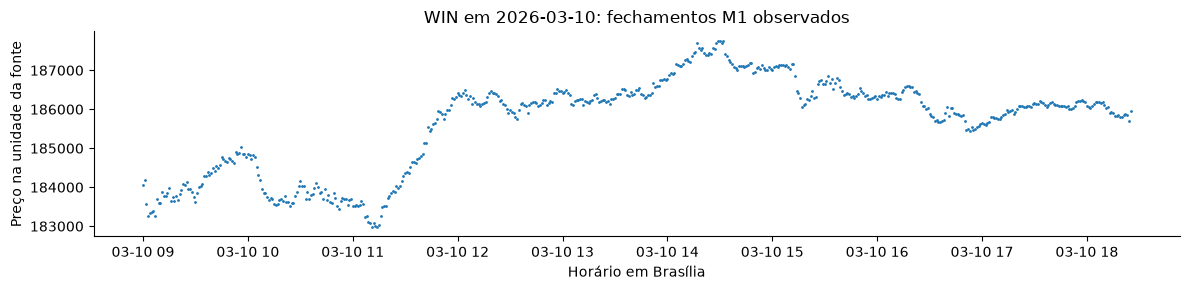

In [14]:
day_start = pd.Timestamp(DIA_EXEMPLO_BRT, tz="America/Sao_Paulo").tz_convert("UTC")
day_end = (pd.Timestamp(DIA_EXEMPLO_BRT, tz="America/Sao_Paulo") + pd.Timedelta(days=1)).tz_convert("UTC")
exemplo_dia = pd.read_parquet(ROOT / f"data/interim/{ATIVO_B3}_m1.parquet",
                             filters=[("datetime", ">=", day_start), ("datetime", "<", day_end)])
if exemplo_dia.empty:
    display(Markdown("**Não há registros nesse dia.** Escolha outra data ou examine as ausências acima."))
else:
    display(exemplo_dia.head())
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(exemplo_dia.datetime.dt.tz_convert("America/Sao_Paulo"), exemplo_dia.close, ".", markersize=2)
    ax.set_title(f"{ATIVO_B3.upper()} em {DIA_EXEMPLO_BRT}: fechamentos M1 observados")
    ax.set_xlabel("Horário em Brasília")
    ax.set_ylabel("Preço na unidade da fonte")
    fig.tight_layout()
    fig.savefig(FIGURES / "03_pregao_exemplo.png", dpi=140)
    plt.show()

## 7. Intervalos sem candles

Um **buraco temporal** é diferente do gap de preço entre fechamento e abertura. Esta seção olha somente os timestamps.

Nos alvos, os intervalos são classificados usando as datas de pregão. Pausas entre sessões não são chamadas de falhas. Intervalos dentro do pregão merecem investigação e também podem refletir interrupções do mercado. O parâmetro `MINUTOS_AUSENTES_PARA_INSPECIONAR` controla o tamanho dos intervalos exibidos, sem alterar os dados.

A completude da janela inicial acima verifica cada minuto, independentemente desse limiar de exibição.

In [15]:
tempos_b3 = pd.read_parquet(ROOT / f"data/interim/{ATIVO_B3}_m1.parquet", columns=["datetime"])
intervalos_b3 = candle_gaps(tempos_b3, min_missing_minutes=MINUTOS_AUSENTES_PARA_INSPECIONAR, calendar=calendario)
display(intervalos_b3.classification.value_counts().to_frame("intervalos"))
display(intervalos_b3.query("classification != 'between_sessions'").head(20))
del tempos_b3

,intervalos
classification,
between_sessions,1364
missing_sessions,3
intraday_investigate,2


,previous_utc,next_utc,missing_minutes,classification
0,2023-06-02 20:54:00+00:00,2023-10-17 19:58:00+00:00,197223,missing_sessions
1,2021-11-12 21:24:00+00:00,2021-12-02 12:00:00+00:00,28235,missing_sessions
2,2022-07-14 20:54:00+00:00,2022-07-28 14:02:00+00:00,19747,missing_sessions
1367,2025-08-21 12:16:00+00:00,2025-08-21 13:26:00+00:00,69,intraday_investigate
1368,2025-06-03 12:03:00+00:00,2025-06-03 12:56:00+00:00,52,intraday_investigate


### Fonte externa selecionada

Não aplicamos automaticamente o calendário de uma bolsa à série CFD que a acompanha. O calendário do índice à vista pode diferir do instrumento fornecido pela Dukascopy.

Assim, os intervalos abaixo têm classificação **sem calendário da fonte**. Eles podem ser pausas regulares, feriados, omissão de candles com volume zero ou falhas de dados. Precisaremos confirmar a causa antes de excluir dias. O perfil por hora UTC mostra quando a fonte tem registros, sem fixar horários estrangeiros em Brasília.

,previous_utc,next_utc,missing_minutes,classification
0,2020-12-24 18:14:00+00:00,2020-12-27 23:00:00+00:00,4605,between_dates_without_source_calendar
1,2024-03-28 20:13:00+00:00,2024-03-31 22:00:00+00:00,4426,between_dates_without_source_calendar
2,2025-04-17 20:13:00+00:00,2025-04-20 22:00:00+00:00,4426,between_dates_without_source_calendar
3,2026-04-02 20:13:00+00:00,2026-04-05 22:00:00+00:00,4426,between_dates_without_source_calendar
4,2023-12-29 21:13:00+00:00,2024-01-01 23:00:00+00:00,4426,between_dates_without_source_calendar
5,2021-12-23 21:13:00+00:00,2021-12-26 23:00:00+00:00,4426,between_dates_without_source_calendar
6,2022-12-23 21:13:00+00:00,2022-12-26 23:00:00+00:00,4426,between_dates_without_source_calendar
7,2022-04-14 20:13:00+00:00,2022-04-17 22:00:00+00:00,4426,between_dates_without_source_calendar
8,2022-12-30 21:13:00+00:00,2023-01-02 23:00:00+00:00,4426,between_dates_without_source_calendar
9,2023-12-22 21:13:00+00:00,2023-12-25 23:00:00+00:00,4426,between_dates_without_source_calendar


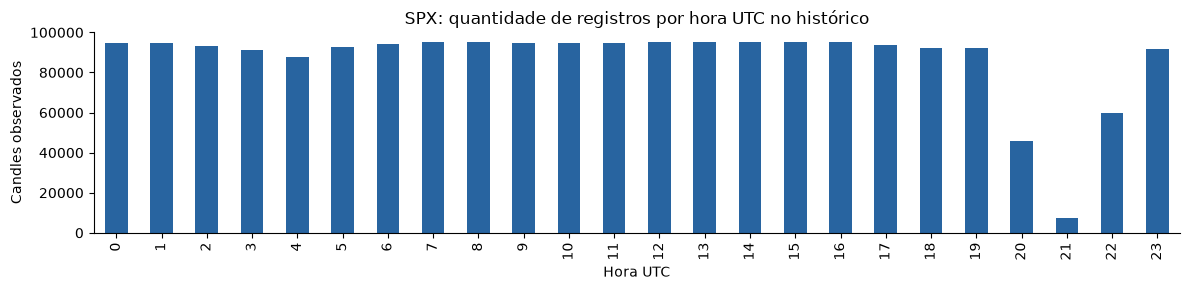

In [16]:
tempos_externos = pd.read_parquet(ROOT / f"data/interim/{ATIVO_EXTERNO}_m1.parquet", columns=["datetime"])
intervalos_externos = candle_gaps(tempos_externos, min_missing_minutes=MINUTOS_AUSENTES_PARA_INSPECIONAR)
display(intervalos_externos.head(15))
fig, ax = plt.subplots(figsize=(12, 3))
perfil_horario = tempos_externos.datetime.dt.hour.value_counts().reindex(range(24), fill_value=0)
perfil_horario.plot.bar(ax=ax, color="#2864a0")
ax.set_title(f"{ATIVO_EXTERNO.upper()}: quantidade de registros por hora UTC no histórico")
ax.set_xlabel("Hora UTC")
ax.set_ylabel("Candles observados")
fig.tight_layout()
fig.savefig(FIGURES / "04_horas_fonte_externa.png", dpi=140)
plt.show()
del tempos_externos

## 8. O que foi ajustado e o que fica sinalizado

Os ajustes automáticos desta etapa são explícitos: nomes/tipos de colunas, conversão de fuso e ordenação; apenas duplicatas idênticas podem ser removidas. As contagens na conversão mostram o que aconteceu nos dados reais.

Dias suspeitos continuam preservados no Parquet de minutos e recebem diagnósticos neste notebook. A tabela diária de modelagem, numa etapa futura, terá de excluir observações sem a informação necessária. Ainda não há uma amostra de treino definida aqui.

Continuam em aberto a confirmação externa do fuso MT5, a cobertura intradiária das fontes externas e as regras de rolagem, especialmente WDO. A causa da abertura tardia do WIN também falta confirmar com a corretora. O gap observado é uma variável `x_open_`: só entra em decisões tomadas depois da abertura, e a previsão do gap usa apenas variáveis `x_pre_`.

In [17]:
display(Markdown(
    f"**Resultado desta execução:** {len(cobertura)} Parquets, "
    f"{int(cobertura.rows.sum()):,} candles e "
    f"{int(padronizacao.duplicates_removed.sum())} duplicatas idênticas removidas. "
    f"A referência tem {len(calendario)} pregões; consulte as ausências internas e os limites das fontes separadamente."
))

def tabela_markdown(frame):
    columns = [str(column) for column in frame.columns]
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join(["---"] * len(columns)) + " |"]
    for row in frame.itertuples(index=False, name=None):
        lines.append("| " + " | ".join(str(value).replace("|", "/") for value in row) + " |")
    return "\n".join(lines)

report = ["# Qualidade inicial dos datasets", "",
          "Gerado pelo notebook notebooks/01_dados_e_qualidade.ipynb com os dados reais.", "",
          f"Foram padronizados {int(cobertura.rows.sum()):,} candles em {len(cobertura)} Parquets UTC. "
          f"Duplicatas idênticas removidas: {int(padronizacao.duplicates_removed.sum())}.", "",
          "## Cobertura observada", "", tabela_markdown(cobertura.round({"parquet_mb": 2})), "",
          "## WIN e WDO", "", tabela_markdown(resumo_b3), "",
          f"Referência: exchange-calendars {metadata.version('exchange-calendars')}, BVMF apenas para datas e aberturas especiais. "
          "Futuros regulares usam 09:00 BRT como referência; a abertura é o primeiro candle observado, e os fechamentos são observados, sem horário fixo.", "",
          "## Aberturas depois da referência", "",
          f"Pregões regulares cujo primeiro candle veio depois da referência. São elegíveis se o atraso for de até {ATRASO_MAXIMO_ABERTURA} minutos "
          f"e a janela de {MINUTOS_JANELA} minutos, contada do primeiro candle, estiver completa.", "",
          tabela_markdown(atrasos.reset_index()), ""]
for asset_id in ["win", "wdo"]:
    internal = blocos_ausentes[asset_id].query("reason == 'missing_session_internal'").sort_values("missing_sessions", ascending=False).head(10)
    report += [f"### Ausências internas — {asset_id.upper()}", "", tabela_markdown(internal), ""]
report += ["## Limites desta auditoria", "",
           "O fuso dos CSVs MT5 é uma hipótese configurável, ainda sem confirmação da corretora. "
           "Datas e horários observados ajudam a avaliar sua coerência, mas não são confirmação externa.", "",
           "Intervalos externos não são falhas confirmadas: ainda precisamos do calendário e das convenções da fonte CFD. "
           "Nenhum preço foi interpolado, nenhum ajuste de rolagem foi aplicado e nenhum dia foi apagado do interim. "
           "O padrão de abertura tardia do WIN indica abertura real mais tarde, mas ainda falta confirmação da corretora. A elegibilidade trata só da qualidade dos dados: rolagem e variáveis ainda podem tirar dias da amostra.", "",
           "Os CSVs brutos são preservados.", ""]
(ROOT / "reports/qualidade_dados.md").write_text("\n".join(report))
print("Resumo salvo em reports/qualidade_dados.md")

**Resultado desta execução:** 15 Parquets, 27,703,105 candles e 0 duplicatas idênticas removidas. A referência tem 1536 pregões; consulte as ausências internas e os limites das fontes separadamente.

Resumo salvo em reports/qualidade_dados.md


### Como continuar usando este notebook

1. Examine as amostras e a comparação de horários.
2. Consulte os maiores blocos ausentes de WIN/WDO e os limites de cada fonte.
3. Troque o ativo e o dia de exemplo na célula de parâmetros para investigar casos concretos.
4. Antes de alterar uma regra de padronização, ajuste a função em `src/abertura`; depois reexecute a conversão e o diagnóstico.
5. Só depois de resolver as pendências de qualidade construiremos as variáveis overnight e os rótulos.

A primeira conversão pode levar alguns minutos. O comando `uv run --locked python -m abertura.interim` oferece a mesma conversão fora do notebook, se necessário.